# DNN Assignment 2, Problem 1: RNN, LSTM and GRU on sequences

Chosen values: hidden size h = 128 (same for RNN, LSTM and GRU), seeds 7, 21 and 42.

Only PyTorch is used and no pretrained weights. Our own RNN, LSTM and GRU cells in §3 are written with matrix operations only. The library layers `nn.RNN`, `nn.LSTM` and `nn.GRU` are used to check those cells and to run the experiments in P1.3 to P1.5, which the brief allows.

Assumptions:
1. The seeds 7, 21 and 42 set the model initialisation, the shuffling and the HAR validation-subject split. The adding-problem data seeds stay at 0, 1 and 2 as given.
2. Parameter counts are worked out both for the brief's h = 64 and for our h = 128.
3. Within each comparison all models get the same optimiser (Adam, lr 1e-3), batch size and 30 epochs.
4. In the adding problem every model is trained with gradient clipping at norm 1.0. Training without clipping only happens in the P1.5(c) ablation.
5. P1.5(c): my student ID 2026AK05422 ends in 2, which is even, so the ablation is gradient clipping (1.0 vs none) for the vanilla RNN at T = 200.
6. For P1.5(a) the library weights are copied into our own cells and unrolled step by step. The fused library layers do not give per-step gradients.
7. The parity check is asserted in float64 on CPU. The float32 differences are only printed.

## §1 Setup

In [2]:
# Imports, run settings and output folders.
import csv, math, os, pickle, random, re, time, urllib.request, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.metrics import confusion_matrix, f1_score
from torch.utils.data import DataLoader, TensorDataset

SMOKE = os.environ.get("SMOKE") == "1"  # local dry run only (1 seed, 1 epoch, small data); never set on Colab
ALL_SEEDS = [7, 21, 42]
SEEDS = ALL_SEEDS[:1] if SMOKE else ALL_SEEDS
EPOCHS = 1 if SMOKE else 30  # same budget for every model in every comparison
H = 128  # chosen hidden size

if Path.cwd().name != "problem1":  # Colab starts in /content: step into the uploaded folder
    _c = [p for p in [Path("problem1"), *Path.cwd().glob("*/problem1")] if p.is_dir()]
    assert _c, f"problem1/ folder not found under {Path.cwd()}; upload the project tree"
    os.chdir(_c[0])
DATA_DIR, FIG_DIR, CACHE_DIR, CSV_PATH = Path("./data"), Path("./figures"), Path("./cache"), Path("../results.csv")
for d in (DATA_DIR, FIG_DIR, CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("torch", torch.__version__, "| device:", DEVICE, "| epochs:", EPOCHS, "| seeds:", SEEDS)


# Wait for queued GPU work to finish so wall-clock timings are real.
def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elif DEVICE.type == "mps":
        torch.mps.synchronize()


# Seed every random generator we use (Python, NumPy, torch CPU and CUDA).
def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

torch 2.14.1+cu130 | device: cuda | epochs: 30 | seeds: [7, 21, 42]


### results.csv logger and run cache
Every finished run adds one row to `../results.csv` (an older row for the same run is replaced) and is pickled to `./cache`. If Colab disconnects, running the notebook again loads the finished runs from the cache. A fresh session has no cache, so everything is trained.

In [3]:
# results.csv has a fixed 12-column layout; KEY identifies one run.
COLUMNS = [
    "problem",
    "model",
    "seed",
    "seq_len",
    "test_acc",
    "macro_f1",
    "test_mse",
    "params",
    "sec_per_epoch",
    "val_loss_nats",
    "bits_per_char",
    "notes",
]
KEY = ("problem", "model", "seed", "seq_len", "notes")


# Add one row to results.csv, or replace the old row for the same run. Writes a temp file first.
def upsert_row(row):
    assert set(row) <= set(COLUMNS), set(row) - set(COLUMNS)
    row = {c: "" if row.get(c) is None else row[c] for c in COLUMNS}
    rows = list(csv.DictReader(open(CSV_PATH, newline=""))) if CSV_PATH.exists() else []
    k = tuple(str(row[c]) for c in KEY)
    rows = [r for r in rows if tuple(r[c] for c in KEY) != k] + [row]
    tmp = CSV_PATH.with_suffix(".tmp")
    with open(tmp, "w", newline="") as f:
        w = csv.DictWriter(f, COLUMNS)
        w.writeheader()
        w.writerows(rows)
    tmp.replace(CSV_PATH)


# Train once and pickle the result; after a disconnect the pickle is loaded instead.
def run_cached(problem, model, seed, seq_len, notes, fn):
    p = CACHE_DIR / (re.sub(r"[^A-Za-z0-9=.-]+", "_", f"{problem}_{model}_s{seed}_L{seq_len}_{notes}") + ".pkl")
    if p.exists():
        out = pickle.load(open(p, "rb"))
    else:
        out = fn()
        out["row"].update(problem=problem, model=model, seed=seed, seq_len=seq_len, notes=notes)
        pickle.dump(out, open(p, "wb"))
    upsert_row(out["row"])
    return out

### Plot style and helpers
Each model keeps its colour in every figure. Multi-seed curves show the mean with a ±1 std band, and lines are labelled at their right end.

In [4]:
# Plot style: one colour per model, light y-grid, no top/right spines.
COLORS = {"RNN": "#E4572E", "LSTM": "#2E86AB", "GRU": "#3BB273", "ref": "#888888"}
plt.rcParams.update(
    {
        "axes.grid": True,
        "axes.grid.axis": "y",
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 12,
        "axes.titlesize": 13,
        "axes.titleweight": "bold",
        "savefig.dpi": 200,
        "savefig.bbox": "tight",
    }
)


# Format a list of seed results as 'mean ± std' (sample std, ddof=1).
def mean_std(xs, fmt="{:.4f}"):
    xs = np.asarray(xs, float)
    if len(xs) < 2:
        return fmt.format(xs.mean())
    return f"{fmt.format(xs.mean())} ± {fmt.format(xs.std(ddof=1))}"  # sample std


# Seed mean as a line, ±1 std as a shaded band.
def band(ax, x, runs, label, color, ls="-"):
    a = np.asarray(runs, float)
    m = a.mean(0)
    s = a.std(0, ddof=1) if len(a) > 1 else np.zeros_like(m)
    ax.plot(x, m, color=color, ls=ls, lw=2)
    ax.fill_between(x, m - s, m + s, color=color, alpha=0.2, lw=0)
    ax._ends = getattr(ax, "_ends", []) + [(x[-1], m[-1], label, color)]


# Write each line's label at its right end, spaced out so labels don't collide.
def end_labels(ax, log=False, gap=0.075):
    f, g = (np.log10, lambda v: 10**v) if log else (lambda v: v, lambda v: v)
    lo, hi = map(f, ax.get_ylim())
    ends = sorted(getattr(ax, "_ends", []), key=lambda e: e[1])
    ys = [f(max(e[1], 1e-30)) for e in ends]
    for i in range(1, len(ys)):
        ys[i] = max(ys[i], ys[i - 1] + gap * (hi - lo))
    for (x, y, lab, c), ty in zip(ends, ys):
        ax.annotate(
            lab,
            xy=(x, y),
            xytext=(1.02, g(ty)),
            textcoords=("axes fraction", "data"),
            color=c,
            va="center",
            fontsize=11,
            annotation_clip=False,
            arrowprops=dict(arrowstyle="-", color=c, lw=0.8, alpha=0.7),
        )
    ax._ends = []


# Grey dashed reference line with a small text label.
def ref_line(ax, y, text, left=False):
    ax.axhline(y, color=COLORS["ref"], ls="--", lw=1)
    ax.annotate(
        text,
        (int(not left), y),
        xycoords=("axes fraction", "data"),
        xytext=(4 if left else -4, 3),
        textcoords="offset points",
        ha="left" if left else "right",
        color=COLORS["ref"],
        fontsize=9,
    )


# Save a figure to ./figures as PNG.
def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")
    print("saved", FIG_DIR / f"{name}.png")

## §2 Data (P1.1)
### HAR: download, load, split by subject, normalise with train-part statistics

In [5]:
# P1.1 HAR. Channel order is fixed by the brief.
CHANNELS = [
    "body_acc_x",
    "body_acc_y",
    "body_acc_z",
    "body_gyro_x",
    "body_gyro_y",
    "body_gyro_z",
    "total_acc_x",
    "total_acc_y",
    "total_acc_z",
]
CLASSES = ["Walking", "Upstairs", "Downstairs", "Sitting", "Standing", "Laying"]
HAR_URL = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"


# Download and unzip UCI HAR the first time; afterwards just return the folder.
def download_har(root=DATA_DIR):
    target = root / "UCI HAR Dataset"
    if not (target / "train" / "Inertial Signals").exists():
        urllib.request.urlretrieve(HAR_URL, root / "har.zip")
        zipfile.ZipFile(root / "har.zip").extractall(root)
        if (root / "UCI HAR Dataset.zip").exists():
            zipfile.ZipFile(root / "UCI HAR Dataset.zip").extractall(root)
    assert (target / "train" / "Inertial Signals").exists(), "HAR extraction failed"
    return target


# Read the 9 inertial channels, labels and subject IDs for the train and test files.
def load_har(root):
    def split(name):
        d = root / name
        X = np.stack([np.loadtxt(d / "Inertial Signals" / f"{c}_{name}.txt", dtype=np.float32) for c in CHANNELS], -1)
        y = np.loadtxt(d / f"y_{name}.txt", dtype=np.int64) - 1  # labels 1..6 -> 0..5
        s = np.loadtxt(d / f"subject_{name}.txt", dtype=np.int64)
        return X, y, s  # X:(N,128,9)

    return (*split("train"), *split("test"))


# Load and check shapes, subjects and labels.
X_tr, y_tr, s_tr, X_te, y_te, s_te = load_har(download_har())
assert X_tr.shape == (7352, 128, 9) and X_te.shape == (2947, 128, 9)
assert len(np.unique(s_tr)) == 21 and len(np.unique(s_te)) == 9 and not set(s_tr) & set(s_te)
assert y_tr.min() == y_te.min() == 0 and y_tr.max() == y_te.max() == 5
print("HAR:", X_tr.shape, X_te.shape, "| train subjects 21, test subjects 9, no overlap")

HAR: (7352, 128, 9) (2947, 128, 9) | train subjects 21, test subjects 9, no overlap


In [6]:
# Validation = 4 of the 21 training subjects, chosen by the seed.
def make_split(subj_train, seed):
    """Returns (train-part indices, val indices, val subjects)."""
    val_subj = np.random.default_rng(seed).choice(np.unique(subj_train), 4, replace=False)
    is_val = np.isin(subj_train, val_subj)
    return np.where(~is_val)[0], np.where(is_val)[0], np.sort(val_subj)


# Per-channel mean and std from the train part only.
def fit_norm(X):
    """Mean and std over windows and time for each channel -> two (9,) arrays."""
    return X.mean(axis=(0, 1)), X.std(axis=(0, 1))


# Standardise with the train-part statistics.
def apply_norm(X, mu, sd):
    return ((X - mu) / sd).astype(np.float32)


# Check the split and the normalisation for all three seeds.
for seed in ALL_SEEDS:
    tri, vai, vs = make_split(s_tr, seed)
    assert len(vs) == 4 and set(vs) <= set(s_tr)
    assert not set(s_tr[tri]) & set(s_tr[vai]) and len(tri) + len(vai) == len(s_tr)
    mu, sg = fit_norm(X_tr[tri].astype(np.float64))
    Z = (X_tr[tri].astype(np.float64) - mu) / sg
    assert mu.shape == sg.shape == (9,)
    assert np.abs(Z.mean(axis=(0, 1))).max() < 1e-4 and np.abs(Z.std(axis=(0, 1)) - 1).max() < 1e-3
    print(f"seed {seed}: val subjects {vs.tolist()} | train-part {len(tri)} windows, val {len(vai)}")


# Loaders for one seed: split by subject, normalise, batch.
def har_loaders(seed, bs=64):
    tri, vai, _ = make_split(s_tr, seed)
    mu, sg = fit_norm(X_tr[tri])
    if SMOKE:
        tri = tri[:512]
    mk = lambda X, y: TensorDataset(torch.from_numpy(apply_norm(X, mu, sg)), torch.from_numpy(y))
    g = torch.Generator().manual_seed(seed)
    return (
        DataLoader(mk(X_tr[tri], y_tr[tri]), bs, shuffle=True, generator=g),
        DataLoader(mk(X_tr[vai], y_tr[vai]), 256),
        DataLoader(mk(X_te, y_te), 256),
    )

seed 7: val subjects [19, 22, 27, 28] | train-part 5913 windows, val 1439
seed 21: val subjects [8, 14, 21, 23] | train-part 5968 windows, val 1384
seed 42: val subjects [3, 16, 22, 23] | train-part 5952 windows, val 1400


### Adding problem: the provided generator and a test for it

In [7]:
# Adding-problem generator as given in the brief (unchanged).
def make_adding(n, T, seed):
    rng = np.random.default_rng(seed)
    x = np.zeros((n, T, 2), dtype=np.float32)
    x[:, :, 0] = rng.random((n, T))
    i1 = rng.integers(0, T // 2, n)
    i2 = rng.integers(T // 2, T, n)
    x[np.arange(n), i1, 1] = 1
    x[np.arange(n), i2, 1] = 1
    y = x[np.arange(n), i1, 0] + x[np.arange(n), i2, 0]
    return x, y.astype(np.float32)


# Two markers per sequence, one in each half, and y equal to the sum of the marked values.
def test_adding(x, y):
    T = x.shape[1]
    m = x[:, :, 1]
    assert (m.sum(1) == 2).all(), "exactly two markers per sequence"
    assert (m[:, : T // 2].sum(1) == 1).all() and (m[:, T // 2 :].sum(1) == 1).all(), "one marker per half"
    assert np.allclose(y, (x[:, :, 0] * m).sum(1), atol=1e-6), "target = sum of marked values"


# Test every split for every T and print the constant-1.0 baseline.
ADD_N = {"train": (10_000, 0), "val": (1_000, 1), "test": (1_000, 2)}  # (n, data seed)
for T in (50, 100, 200, 400):
    for n, ds in ADD_N.values():
        test_adding(*make_adding(n, T, ds))
    base = float(((make_adding(1000, T, 2)[1] - 1.0) ** 2).mean())
    assert 0.14 < base < 0.19
    print(f"T={T}: constant-1.0 predictor test MSE = {base:.4f}")

T=50: constant-1.0 predictor test MSE = 0.1754
T=100: constant-1.0 predictor test MSE = 0.1697
T=200: constant-1.0 predictor test MSE = 0.1679
T=400: constant-1.0 predictor test MSE = 0.1527


### P1-F1 Class balance (seed 7 split)

saved figures/p1_fig01_class_balance.png


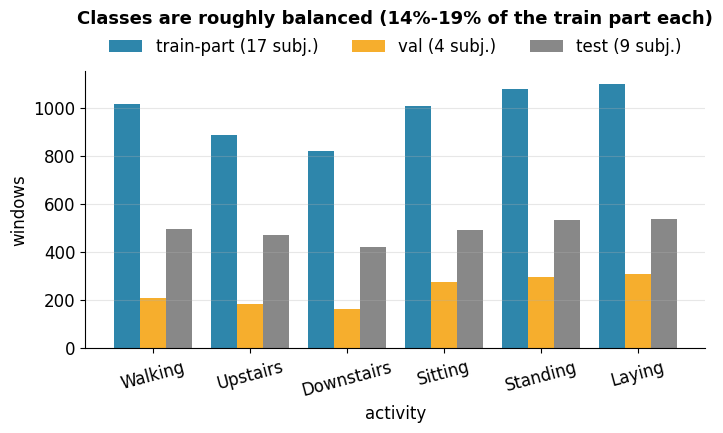

In [8]:
# P1-F1: class counts in the train part, validation and test (seed 7 split).
tri7, vai7, _ = make_split(s_tr, 7)
cnt = lambda y: np.bincount(y, minlength=6)
fig, ax = plt.subplots(figsize=(8, 3.6))
parts = [
    ("train-part (17 subj.)", y_tr[tri7], "#2E86AB"),
    ("val (4 subj.)", y_tr[vai7], "#F6AE2D"),
    ("test (9 subj.)", y_te, "#888888"),
]
for k, (lab, y, col) in enumerate(parts):
    ax.bar(np.arange(6) + (k - 1) * 0.27, cnt(y), 0.27, label=lab, color=col)
ax.set_xticks(range(6), CLASSES, rotation=15)
ax.set_xlabel("activity")
ax.set_ylabel("windows")
share = cnt(y_tr[tri7]) / len(tri7)
ax.set_title(f"Classes are roughly balanced ({share.min():.0%}-{share.max():.0%} of the train part each)", pad=34)
ax.legend(frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0))
save(fig, "p1_fig01_class_balance")
plt.show()

## §3 Cells from scratch (P1.2)

The parameters use PyTorch's names and shapes (`W_ih`, `W_hh`, `b_ih`, `b_hh`), so weights can be copied across directly. The cells only use `x @ W.T + b`, `sigmoid`, `tanh`, `chunk` and element-wise operations.

* RNN: $h_t=\tanh(W_{ih}x_t+b_{ih}+W_{hh}h_{t-1}+b_{hh})$
* LSTM (gates i, f, g, o): $c_t=f\odot c_{t-1}+i\odot g,\; h_t=o\odot\tanh(c_t)$
* GRU (gates r, z, n): $n_t=\tanh(W_{in}x_t+b_{in}+r_t\odot(W_{hn}h_{t-1}+b_{hn})),\; h_t=(1-z_t)\odot n_t+z_t\odot h_{t-1}$. Here $r$ also multiplies $b_{hn}$, as in PyTorch.

In [9]:
# Common parts of our three cells. Same weight names and shapes as PyTorch, so weights copy over 1:1.
class _Cell(nn.Module):
    G = 1  # number of gate blocks

    def __init__(self, d, h):
        super().__init__()
        self.h = h
        k = 1.0 / math.sqrt(h)
        self.W_ih = nn.Parameter(torch.empty(self.G * h, d).uniform_(-k, k))
        self.W_hh = nn.Parameter(torch.empty(self.G * h, h).uniform_(-k, k))
        self.b_ih = nn.Parameter(torch.empty(self.G * h).uniform_(-k, k))
        self.b_hh = nn.Parameter(torch.empty(self.G * h).uniform_(-k, k))

    @classmethod
    def from_torch(cls, layer):
        c = cls(layer.input_size, layer.hidden_size).to(layer.weight_ih_l0.dtype)
        with torch.no_grad():
            for own, lib in (
                ("W_ih", "weight_ih_l0"),
                ("W_hh", "weight_hh_l0"),
                ("b_ih", "bias_ih_l0"),
                ("b_hh", "bias_hh_l0"),
            ):
                getattr(c, own).copy_(getattr(layer, lib))
        return c

    def init_state(self, B, like):
        return torch.zeros(B, self.h, dtype=like.dtype)


# Vanilla RNN cell, one gate block.
class MyRNNCell(_Cell):
    G = 1

    def forward(self, x, h):  # x:(B,d) h:(B,h) -> (B,h)
        return torch.tanh(x @ self.W_ih.T + self.b_ih + h @ self.W_hh.T + self.b_hh)


# LSTM cell, four gate blocks in PyTorch order i, f, g, o. State is (h, c).
class MyLSTMCell(_Cell):
    G = 4

    def init_state(self, B, like):
        z = super().init_state(B, like)
        return (z, z.clone())

    def forward(self, x, state):
        h, c = state  # x:(B,d)  h,c:(B,h)
        gates = x @ self.W_ih.T + self.b_ih + h @ self.W_hh.T + self.b_hh  # (B,4h)
        i, f, g, o = gates.chunk(4, dim=-1)  # 4 x (B,h), order i,f,g,o
        i, f, o, g = torch.sigmoid(i), torch.sigmoid(f), torch.sigmoid(o), torch.tanh(g)
        c = f * c + i * g  # (B,h)
        h = o * torch.tanh(c)  # (B,h)
        return (h, c)


# GRU cell, three gate blocks in PyTorch order r, z, n.
class MyGRUCell(_Cell):
    G = 3

    def forward(self, x, h):  # x:(B,d) h:(B,h) -> (B,h)
        ir, iz, in_ = (x @ self.W_ih.T + self.b_ih).chunk(3, dim=-1)  # 3 x (B,h), order r,z,n
        hr, hz, hn = (h @ self.W_hh.T + self.b_hh).chunk(3, dim=-1)  # hn includes b_hn
        r, z = torch.sigmoid(ir + hr), torch.sigmoid(iz + hz)
        n = torch.tanh(in_ + r * hn)  # r multiplies (W_hn h + b_hn)
        return (1 - z) * n + z * h


# Step a cell through the sequence one time step at a time. keep_grad keeps dL/dh_t for P1.5a.
def unroll(cell, x, keep_grad=False):
    """x:(B,T,d) -> outputs (B,T,h), final state, list of per-step h."""
    state, hs = cell.init_state(x.shape[0], x), []
    for t in range(x.shape[1]):
        state = cell(x[:, t], state)
        h = state[0] if isinstance(state, tuple) else state
        if keep_grad:
            h.retain_grad()
        hs.append(h)
    return torch.stack(hs, 1), state, hs

### Parity with the library layers (asserted in float64 on CPU, float32 printed)

In [10]:
# P1.2 parity: our cells against the library layers, same weights, same input.
LIB = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}
OWN = {"RNN": MyRNNCell, "LSTM": MyLSTMCell, "GRU": MyGRUCell}


# Largest absolute difference over all outputs and the final state.
@torch.no_grad()
def parity(kind, dtype, d=9, h=128, B=8, T=128):
    torch.manual_seed(0)
    layer = LIB[kind](d, h, batch_first=True).to(dtype)
    x = torch.randn(B, T, d, dtype=dtype)
    out_ref, st_ref = layer(x)
    out, st = unroll(OWN[kind].from_torch(layer), x)[:2]
    st, st_ref = (st, st_ref) if kind == "LSTM" else ((st,), (st_ref,))
    return max([(out - out_ref).abs().max().item()] + [(a - b[0]).abs().max().item() for a, b in zip(st, st_ref)])


for kind in LIB:
    d64, d32 = parity(kind, torch.float64), parity(kind, torch.float32)
    assert d64 < 1e-5, (kind, d64)
    print(f"{kind:5s} max|Δ| (outputs, final h and c) float64 = {d64:.2e} (assert < 1e-5) | float32 = {d32:.2e}")

RNN   max|Δ| (outputs, final h and c) float64 = 3.33e-16 (assert < 1e-5) | float32 = 1.64e-07
LSTM  max|Δ| (outputs, final h and c) float64 = 5.55e-17 (assert < 1e-5) | float32 = 7.45e-08
GRU   max|Δ| (outputs, final h and c) float64 = 1.67e-16 (assert < 1e-5) | float32 = 5.96e-08


### Parameter counts

One gate block has $h(d+h)+h$ parameters: $hd$ input weights, $h^2$ recurrent weights and one bias of size $h$. With $g$ blocks the hand count is $g\,(h(d+h)+h)$, where $g=1$ for the RNN, 4 for the LSTM and 3 for the GRU. PyTorch stores two bias vectors, $b_{ih}$ and $b_{hh}$, to stay compatible with cuDNN. Only their sum matters, so the second one is redundant, and it adds $g\cdot h$ to the count.

| Cell | g | hand, h=64 | PyTorch, h=64 | hand, h=128 | PyTorch, h=128 |
|---|---|---|---|---|---|
| RNN | 1 | 4,736 | 4,800 | 17,664 | 17,792 |
| LSTM | 4 | 18,944 | 19,200 | 70,656 | 71,168 |
| GRU | 3 | 14,208 | 14,400 | 52,992 | 53,376 |

In [11]:
# Parameter counts: hand formula vs nn.* vs our cells, for h = 64 and h = 128.
rows = []
for h in (64, 128):
    for kind, g in {"RNN": 1, "LSTM": 4, "GRU": 3}.items():
        hand = g * (h * (9 + h) + h)
        lib_n = sum(p.numel() for p in LIB[kind](9, h).parameters())
        own_n = sum(p.numel() for p in OWN[kind](9, h).parameters())
        assert lib_n == own_n == hand + g * h, (kind, h)
        rows.append((kind, h, hand, lib_n, own_n))
assert [r[2] for r in rows] == [4736, 18944, 14208, 17664, 70656, 52992]
display(pd.DataFrame(rows, columns=["cell", "h", "hand (one bias)", "nn.* sum(numel)", "own cell sum(numel)"]))

,cell,h,hand (one bias),nn.* sum(numel),own cell sum(numel)
0,RNN,64,4736,4800,4800
1,LSTM,64,18944,19200,19200
2,GRU,64,14208,14400,14400
3,RNN,128,17664,17792,17792
4,LSTM,128,70656,71168,71168
5,GRU,128,52992,53376,53376


## §4 Experiments
### Models and the training loop
Each model is one library recurrent layer (no dropout) followed by a `Linear` on the last hidden state. Every run uses Adam with lr 1e-3. The best epoch is picked on the validation set, and the test set is evaluated once with those weights, which are kept in memory.

In [12]:
# Recurrent layer, last hidden state, linear head. Used for both HAR and the adding problem.
class SeqModel(nn.Module):
    """x:(B,T,in) -> last hidden state (B,h) -> Linear -> (B,out); squeezed to (B,) when out == 1."""

    def __init__(self, kind, in_dim, h, out_dim):
        super().__init__()
        self.rnn = LIB[kind](in_dim, h, batch_first=True)
        self.head = nn.Linear(h, out_dim)

    def forward(self, x):
        y = self.head(self.rnn(x)[0][:, -1])  # (B,T,h) -> (B,h) -> (B,out)
        return y.squeeze(-1) if y.shape[-1] == 1 else y


# Total number of parameters.
def n_params(m):
    return sum(p.numel() for p in m.parameters())


# Model sizes used in P1-T1.
for k, n in {"RNN": 18566, "LSTM": 71942, "GRU": 54150}.items():  # library layer + Linear(128, 6)
    m = SeqModel(k, 9, 128, 6)
    assert n_params(m) == n and m(torch.randn(3, 128, 9)).shape == (3, 6)


# Mean loss on a loader; for classification also accuracy, macro-F1 and predictions.
@torch.no_grad()
def evaluate(model, dl, task):
    model.eval()
    tot, n, preds, ys = 0.0, 0, [], []
    for x, y in dl:
        x, y = x.to(DEVICE), y.to(DEVICE)
        out = model(x)
        tot += float(F.cross_entropy(out, y, reduction="sum") if task == "cls" else F.mse_loss(out, y, reduction="sum"))
        n += len(y)
        if task == "cls":
            preds.append(out.argmax(1).cpu())
            ys.append(y.cpu())
    res = dict(loss=tot / n)
    if task == "cls":
        p, t = torch.cat(preds).numpy(), torch.cat(ys).numpy()
        res.update(acc=float((p == t).mean()), f1=float(f1_score(t, p, average="macro")), y_pred=p)
    return res


# Training loop shared by every Problem 1 run.
def fit(model, train_dl, val_dl, task, epochs, clip):
    """Adam lr 1e-3. Keeps the epoch with the best val accuracy (cls) or val MSE (reg).
    history['grad_norm'] is the mean gradient norm per step, measured before clipping."""
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    lossf = F.cross_entropy if task == "cls" else F.mse_loss
    hist = dict(train_loss=[], val_loss=[], grad_norm=[])
    best, best_state, times = None, None, []
    for ep in range(epochs):
        model.train()
        sync()
        t0 = time.time()
        tot, gn, n, nb = 0.0, 0.0, 0, 0
        for x, y in train_dl:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            loss = lossf(model(x), y)
            loss.backward()
            gn += float(nn.utils.clip_grad_norm_(model.parameters(), clip or float("inf")))  # returns pre-clip norm
            opt.step()
            tot, n, nb = tot + loss.item() * len(y), n + len(y), nb + 1
        sync()
        times.append(time.time() - t0)
        assert math.isfinite(tot), f"non-finite training loss at epoch {ep}"
        ev = evaluate(model, val_dl, task)
        metric = ev["acc"] if task == "cls" else -ev["loss"]  # higher is better
        hist["train_loss"].append(tot / n)
        hist["val_loss"].append(ev["loss"])
        hist["grad_norm"].append(gn / nb)
        if best is None or metric > best:
            best, best_state = metric, {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return hist, float(np.mean(times))

### P1.3 HAR classification
RNN, LSTM and GRU get the same budget: Adam lr 1e-3, batch 64, 30 epochs, cross-entropy, h = 128, one layer, no dropout and no clipping. Each seed also has its own validation split and normalisation.

In [13]:
# One HAR run: train, then evaluate the test set once at the best validation epoch.
def run_har(kind, seed, h=H):
    seed_all(seed)
    model = SeqModel(kind, 9, h, 6).to(DEVICE)
    train_dl, val_dl, test_dl = har_loaders(seed, bs=64)
    hist, spe = fit(model, train_dl, val_dl, "cls", EPOCHS, clip=None)
    te = evaluate(model, test_dl, "cls")  # test set used once, with the best-val weights
    row = dict(test_acc=te["acc"], macro_f1=te["f1"], params=n_params(model), sec_per_epoch=spe)
    return dict(row=row, history=hist, artifacts=dict(y_pred=te["y_pred"].astype(np.int8)))


t0 = time.time()
# 3 models x 3 seeds.
HAR = {k: [run_cached("P1.3", k, s, 128, f"h={H}", lambda k=k, s=s: run_har(k, s)) for s in SEEDS] for k in LIB}
for k in LIB:
    for s, o in zip(SEEDS, HAR[k]):
        r = o["row"]
        print(
            f"P1.3 {k:4s} seed {s:2d}: acc {r['test_acc']:.4f} f1 {r['macro_f1']:.4f} {r['sec_per_epoch']:.2f}s/epoch"
        )
print(f"P1.3 done in {time.time() - t0:.0f}s")

P1.3 RNN  seed  7: acc 0.7757 f1 0.7725 0.31s/epoch
P1.3 RNN  seed 21: acc 0.8025 f1 0.7996 0.29s/epoch
P1.3 RNN  seed 42: acc 0.8388 f1 0.8362 0.29s/epoch
P1.3 LSTM seed  7: acc 0.9121 f1 0.9125 0.39s/epoch
P1.3 LSTM seed 21: acc 0.9233 f1 0.9250 0.39s/epoch
P1.3 LSTM seed 42: acc 0.8968 f1 0.8968 0.39s/epoch
P1.3 GRU  seed  7: acc 0.9080 f1 0.9090 0.30s/epoch
P1.3 GRU  seed 21: acc 0.9186 f1 0.9202 0.30s/epoch
P1.3 GRU  seed 42: acc 0.9080 f1 0.9077 0.29s/epoch
P1.3 done in 105s


**P1-T1** HAR results, h=128, 3 seeds, 30 epochs, device cuda

,model,test acc (mean ± std),macro-F1 (mean ± std),params,s/epoch
0,RNN,0.8057 ± 0.0317,0.8028 ± 0.0319,"18,566",0.30
1,LSTM,0.9108 ± 0.0133,0.9114 ± 0.0141,"71,942",0.39
2,GRU,0.9115 ± 0.0061,0.9123 ± 0.0069,"54,150",0.30


best run LSTM seed 21; most confused: Standing -> Sitting (20%)
saved figures/p1_fig03_har_results.png


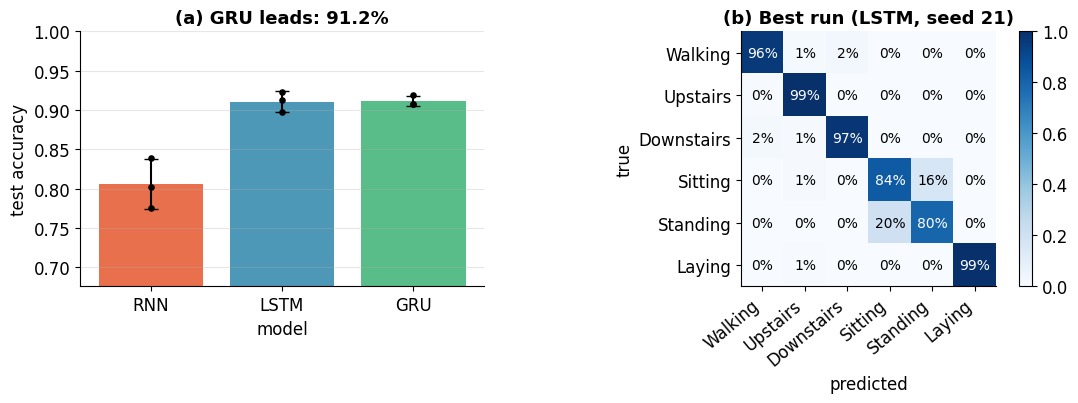

In [14]:
# P1-T1 table, then P1-F3: accuracy bars and the confusion matrix of the best single run.
T1 = pd.DataFrame(
    [
        (
            k,
            mean_std([o["row"]["test_acc"] for o in HAR[k]]),
            mean_std([o["row"]["macro_f1"] for o in HAR[k]]),
            f"{HAR[k][0]['row']['params']:,}",
            f"{np.mean([o['row']['sec_per_epoch'] for o in HAR[k]]):.2f}",
        )
        for k in LIB
    ],
    columns=["model", "test acc (mean ± std)", "macro-F1 (mean ± std)", "params", "s/epoch"],
)
display(Markdown(f"**P1-T1** HAR results, h={H}, {len(SEEDS)} seeds, {EPOCHS} epochs, device {DEVICE.type}"), T1)

accs = {k: np.array([o["row"]["test_acc"] for o in HAR[k]]) for k in LIB}
best_k, best_i = max(((k, i) for k in LIB for i in range(len(SEEDS))), key=lambda ki: accs[ki[0]][ki[1]])
lead = max(LIB, key=lambda k: accs[k].mean())
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw=dict(width_ratios=[1, 1.15]))
for i, k in enumerate(LIB):
    a = accs[k]
    ax1.bar(i, a.mean(), yerr=a.std(ddof=1) if len(a) > 1 else 0, color=COLORS[k], alpha=0.85, capsize=5)
    ax1.scatter(np.full(len(a), i), a, color="black", s=14, zorder=3)
ax1.set_xticks(range(3), list(LIB))
ax1.set_xlabel("model")
ax1.set_ylabel("test accuracy")
ax1.set_ylim(min(a.min() for a in accs.values()) - 0.1, 1.0)
ax1.set_title(f"(a) {lead} leads: {accs[lead].mean():.1%}")
cm = confusion_matrix(y_te, HAR[best_k][best_i]["artifacts"]["y_pred"].astype(int), labels=range(6)).astype(float)
cm /= cm.sum(1, keepdims=True)  # row-normalised
im = ax2.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax2.grid(False)
for i in range(6):
    for j in range(6):
        ax2.text(
            j, i, f"{cm[i, j]:.0%}", ha="center", va="center", color="white" if cm[i, j] > 0.5 else "black", fontsize=10
        )
ax2.set_xticks(range(6), CLASSES, rotation=40, ha="right")
ax2.set_yticks(range(6), CLASSES)
ax2.set_xlabel("predicted")
ax2.set_ylabel("true")
ax2.set_title(f"(b) Best run ({best_k}, seed {SEEDS[best_i]})")
fig.colorbar(im, ax=ax2, fraction=0.046)
off = cm - np.diag(np.diag(cm))
wi, wj = np.unravel_index(off.argmax(), off.shape)
print(f"best run {best_k} seed {SEEDS[best_i]}; most confused: {CLASSES[wi]} -> {CLASSES[wj]} ({off.max():.0%})")
fig.tight_layout()
save(fig, "p1_fig03_har_results")
plt.show()

### P1.4 Adding problem
RNN, LSTM and GRU get the same budget: Adam lr 1e-3, batch 128, 30 epochs, MSE loss, h = 128, and gradient clipping at norm 1.0 for all three. The data seeds 0, 1 and 2 are fixed, so our seeds only change the initialisation and shuffling. We count a run as solved when its test MSE is below 0.05. Always predicting 1.0 gives about 0.167.

In [15]:
# P1.4 adding problem.
ADD_T = [50, 100, 200, 400]
_ADD_DATA = {}


# Loaders for one T. The data is generated once per T and shared by all models and seeds.
def add_loaders(T, seed, bs=128):
    if T not in _ADD_DATA:
        _ADD_DATA[T] = {s: [torch.from_numpy(a) for a in make_adding(n, T, ds)] for s, (n, ds) in ADD_N.items()}
    d = _ADD_DATA[T]
    xtr, ytr = (a[:512] for a in d["train"]) if SMOKE else d["train"]
    g = torch.Generator().manual_seed(seed)
    return (
        DataLoader(TensorDataset(xtr, ytr), bs, shuffle=True, generator=g),
        DataLoader(TensorDataset(*d["val"]), 500),
        DataLoader(TensorDataset(*d["test"]), 500),
    )


# One adding run. keep_states stores the initial and trained weights (used for T=100, seed 7 in P1.5a).
def run_add(kind, seed, T, clip=1.0, keep_states=False):
    seed_all(seed)
    model = SeqModel(kind, 2, H, 1).to(DEVICE)
    cpu_state = lambda: {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    art = dict(init_state=cpu_state()) if keep_states else {}
    train_dl, val_dl, test_dl = add_loaders(T, seed)
    hist, spe = fit(model, train_dl, val_dl, "reg", EPOCHS, clip)
    if keep_states:
        art["trained_state"] = cpu_state()  # best-val checkpoint
    te = evaluate(model, test_dl, "reg")
    return dict(row=dict(test_mse=te["loss"], params=n_params(model), sec_per_epoch=spe), history=hist, artifacts=art)


t0 = time.time()
# 4 lengths x 3 models x 3 seeds = 36 runs.
ADD = {}
for T in ADD_T:
    for k in LIB:
        ADD[(k, T)] = [
            run_cached(
                "P1.4", k, s, T, f"h={H}", lambda k=k, s=s, T=T: run_add(k, s, T, keep_states=(T, s) == (100, 7))
            )
            for s in SEEDS
        ]
        print(f"P1.4 T={T:3d} {k:4s}: test MSE " + ", ".join(f"{o['row']['test_mse']:.4f}" for o in ADD[(k, T)]))
print(f"P1.4 done in {time.time() - t0:.0f}s")

P1.4 T= 50 RNN : test MSE 0.1743, 0.1743, 0.1690
P1.4 T= 50 LSTM: test MSE 0.0105, 0.0027, 0.0083
P1.4 T= 50 GRU : test MSE 0.0004, 0.0010, 0.0024
P1.4 T=100 RNN : test MSE 0.1700, 0.1701, 0.1700
P1.4 T=100 LSTM: test MSE 0.1687, 0.0814, 0.0159
P1.4 T=100 GRU : test MSE 0.0011, 0.0013, 0.0014
P1.4 T=200 RNN : test MSE 0.1686, 0.1681, 0.1689
P1.4 T=200 LSTM: test MSE 0.1684, 0.1684, 0.1684
P1.4 T=200 GRU : test MSE 0.0005, 0.0007, 0.0005
P1.4 T=400 RNN : test MSE 0.1535, 0.1543, 0.1540
P1.4 T=400 LSTM: test MSE 0.1537, 0.1537, 0.1540
P1.4 T=400 GRU : test MSE 0.0020, 0.0818, 0.0009
P1.4 done in 601s


**P1-T2** Adding problem, test MSE (mean ± std over 3 seeds); baseline ≈ 0.167

,model,T=50,T=100,T=200,T=400
0,RNN,0.1725 ± 0.0030,0.1700 ± 0.0001,0.1685 ± 0.0004,0.1540 ± 0.0004
1,LSTM,0.0072 ± 0.0040,0.0887 ± 0.0766,0.1684 ± 0.0000,0.1538 ± 0.0002
2,GRU,0.0013 ± 0.0010,0.0013 ± 0.0001,0.0006 ± 0.0001,0.0282 ± 0.0464


**P1-T3** Solved runs (test MSE < 0.05)

,model,T=50,T=100,T=200,T=400
0,RNN,0/3,0/3,0/3,0/3
1,LSTM,3/3,1/3,0/3,0/3
2,GRU,3/3,3/3,3/3,2/3


saved figures/p1_fig04_adding.png


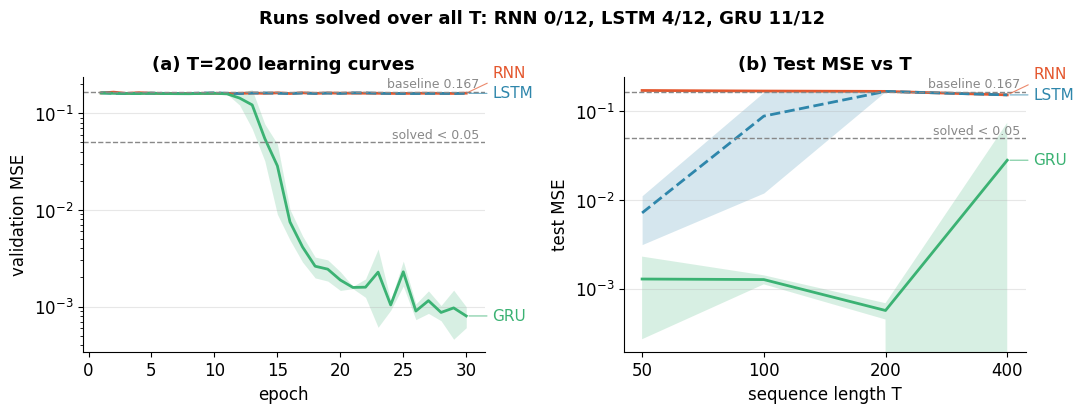

In [16]:
# P1-T2 (test MSE), P1-T3 (solved runs) and P1-F4.
mse = {key: [o["row"]["test_mse"] for o in v] for key, v in ADD.items()}
solved = {key: sum(m < 0.05 for m in v) for key, v in mse.items()}
cols = ["model"] + [f"T={T}" for T in ADD_T]
T2 = pd.DataFrame([[k] + [mean_std(mse[(k, T)]) for T in ADD_T] for k in LIB], columns=cols)
T3 = pd.DataFrame([[k] + [f"{solved[(k, T)]}/{len(SEEDS)}" for T in ADD_T] for k in LIB], columns=cols)
display(Markdown(f"**P1-T2** Adding problem, test MSE (mean ± std over {len(SEEDS)} seeds); baseline ≈ 0.167"), T2)
display(Markdown("**P1-T3** Solved runs (test MSE < 0.05)"), T3)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
for k in LIB:
    ls = "--" if k == "LSTM" else "-"
    band(ax1, np.arange(1, EPOCHS + 1), [o["history"]["val_loss"] for o in ADD[(k, 200)]], k, COLORS[k], ls)
    band(ax2, ADD_T, np.array([mse[(k, T)] for T in ADD_T]).T, k, COLORS[k], ls)
for ax in (ax1, ax2):
    ax.set_yscale("log")
    ref_line(ax, 0.167, "baseline 0.167")
    ref_line(ax, 0.05, "solved < 0.05")
    end_labels(ax, log=True)
ax1.set_xlabel("epoch")
ax1.set_ylabel("validation MSE")
ax1.set_title("(a) T=200 learning curves")
ax2.set_xscale("log")
ax2.set_xticks(ADD_T, ADD_T)
ax2.minorticks_off()
ax2.set_xlabel("sequence length T")
ax2.set_ylabel("test MSE")
ax2.set_title("(b) Test MSE vs T")
n_all = len(ADD_T) * len(SEEDS)
fig.suptitle(
    "Runs solved over all T: " + ", ".join(f"{k} {sum(solved[(k, T)] for T in ADD_T)}/{n_all}" for k in LIB),
    fontweight="bold",
    fontsize=13,
)
fig.tight_layout()
save(fig, "p1_fig04_adding")
plt.show()

## P1.5 Gradients, ablation, analysis
### (a) Gradient norm ‖∂L/∂h_t‖ vs t at T = 100, before and after training
The library layers run the whole recurrence inside one kernel, so a gradient on their `output[:, t]` only shows the direct path from that output. Instead we take the untrained model (seed 7 initialisation) and the trained one (P1.4, T = 100, seed 7, best validation epoch) and copy their weights into our P1.2 cell. The cell is unrolled step by step on 256 test sequences with `retain_grad()` on every `h_t`. The loss is the squared error at the last step, through the same output head, summed over the batch. After `backward()` we plot the batch mean of ‖∂L/∂h_t‖₂ for each t.

RNN  ‖∂L/∂h_t‖ at t=1: before 4.6e-22, after 9.0e-20 | at t=100: before 1.2e+00, after 3.9e-01
LSTM ‖∂L/∂h_t‖ at t=1: before 1.3e-20, after 1.0e-05 | at t=100: before 1.1e+00, after 4.4e-01
GRU  ‖∂L/∂h_t‖ at t=1: before 4.3e-20, after 2.2e-02 | at t=100: before 1.1e+00, after 3.8e-02
grad(t=1) / grad(t=100) after training: {'RNN': '2.3e-19', 'LSTM': '2.3e-05', 'GRU': '5.8e-01'}
saved figures/p1_fig05_grad_norms.png


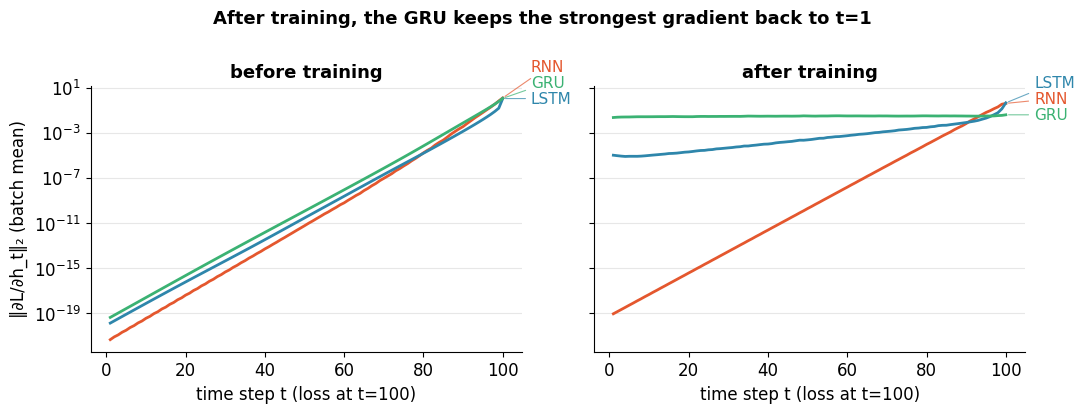

In [17]:
# Load the weights into our own cell, unroll, back-propagate the loss and return mean ||dL/dh_t|| for each t.
def grad_curve(kind, state, T=100, n=256):
    m = SeqModel(kind, 2, H, 1)
    m.load_state_dict(state)
    cell = OWN[kind].from_torch(m.rnn)  # our cell, with the library weights copied in
    x, y = (torch.from_numpy(a) for a in make_adding(n, T, 2))
    hs = unroll(cell, x, keep_grad=True)[2]  # T tensors (n,h)
    pred = m.head(hs[-1]).squeeze(-1)  # (n,)
    assert torch.allclose(pred, m(x), atol=1e-4), "own-cell unroll must reproduce the library model"
    ((pred - y) ** 2).sum().backward()
    return torch.stack([h.grad.norm(dim=1).mean() for h in hs]).numpy()  # (T,)


# Before = initial weights, after = best checkpoint, both from the T=100 seed-7 run.
GRAD = {}
for k in LIB:
    art = ADD[(k, 100)][0]["artifacts"]  # seed 7
    GRAD[k] = {ph: grad_curve(k, art[st]) for ph, st in (("before", "init_state"), ("after", "trained_state"))}
    g = GRAD[k]
    print(
        f"{k:4s} ‖∂L/∂h_t‖ at t=1: before {g['before'][0]:.1e}, after {g['after'][0]:.1e} | "
        f"at t=100: before {g['before'][-1]:.1e}, after {g['after'][-1]:.1e}"
    )
ratio = {k: GRAD[k]["after"][0] / GRAD[k]["after"][-1] for k in LIB}
print("grad(t=1) / grad(t=100) after training:", {k: f"{v:.1e}" for k, v in ratio.items()})

# P1-F5: one panel before training, one after.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, ph in zip(axes, ("before", "after")):
    for k in LIB:
        g = np.maximum(GRAD[k][ph], 1e-30)
        ax.plot(np.arange(1, 101), g, color=COLORS[k], lw=2)
        ax._ends = getattr(ax, "_ends", []) + [(100, g[-1], k, COLORS[k])]
    ax.set_yscale("log")
    end_labels(ax, log=True, gap=0.06)
    ax.set_xlabel("time step t (loss at t=100)")
    ax.set_title(f"{ph} training")
axes[0].set_ylabel("‖∂L/∂h_t‖₂ (batch mean)")
best_g = max(LIB, key=ratio.get)
fig.suptitle(f"After training, the {best_g} keeps the strongest gradient back to t=1", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "p1_fig05_grad_norms")
plt.show()

### (b) Hidden-size sweep, LSTM and GRU on HAR
h ∈ {16, 32, 64, 128} with the P1.3 protocol and budget. The h = 128 runs are the ones from P1.3.

P1.5b done in 187s


,model,h,params,test acc (mean ± std)
0,LSTM,16,"1,830",0.8588 ± 0.0097
1,LSTM,32,"5,702",0.8689 ± 0.0124
2,LSTM,64,"19,590",0.8984 ± 0.0073
3,LSTM,128,"71,942",0.9108 ± 0.0133
4,GRU,16,"1,398",0.8792 ± 0.0160
5,GRU,32,"4,326",0.8966 ± 0.0050
6,GRU,64,"14,790",0.9083 ± 0.0098
7,GRU,128,"54,150",0.9115 ± 0.0061


saved figures/p1_fig06_hidden_sweep.png


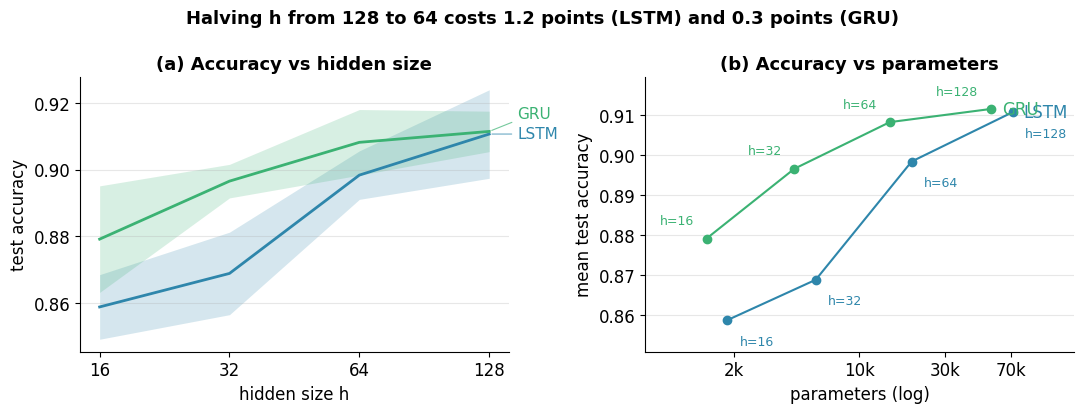

In [18]:
# P1.5b: train h = 16, 32 and 64; h = 128 is reused from P1.3.
SWEEP_H = [16, 32, 64, 128]
SW = {k: {128: HAR[k]} for k in ("LSTM", "GRU")}
t0 = time.time()
for k in SW:
    for h in SWEEP_H[:-1]:
        SW[k][h] = [run_cached("P1.5b", k, s, 128, f"h={h}", lambda k=k, s=s, h=h: run_har(k, s, h)) for s in SEEDS]
print(f"P1.5b done in {time.time() - t0:.0f}s")
acc_h = {k: {h: [o["row"]["test_acc"] for o in SW[k][h]] for h in SWEEP_H} for k in SW}
par_h = {k: {h: SW[k][h][0]["row"]["params"] for h in SWEEP_H} for k in SW}
display(
    pd.DataFrame(
        [(k, h, f"{par_h[k][h]:,}", mean_std(acc_h[k][h])) for k in SW for h in SWEEP_H],
        columns=["model", "h", "params", "test acc (mean ± std)"],
    )
)

# P1-F6: (a) accuracy vs h, (b) accuracy vs parameter count.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
for k in SW:
    band(ax1, SWEEP_H, np.array([acc_h[k][h] for h in SWEEP_H]).T, k, COLORS[k])
    xs, ys = [par_h[k][h] for h in SWEEP_H], [np.mean(acc_h[k][h]) for h in SWEEP_H]
    ax2.plot(xs, ys, "-o", color=COLORS[k], lw=1.5)
    for h, x, y in zip(SWEEP_H, xs, ys):
        ax2.annotate(
            f"h={h}",
            (x, y),
            xytext=(-9, 10) if k == "GRU" else (9, -18),
            textcoords="offset points",
            fontsize=9,
            ha="right" if k == "GRU" else "left",
            color=COLORS[k],
        )
    ax2.annotate(
        k,
        (xs[-1], ys[-1]),
        xytext=(8, 0),
        textcoords="offset points",
        va="center",
        color=COLORS[k],
        annotation_clip=False,
    )
ax1.set_xscale("log", base=2)
ax1.set_xticks(SWEEP_H, SWEEP_H)
ax1.minorticks_off()
end_labels(ax1)
ax1.set_xlabel("hidden size h")
ax1.set_ylabel("test accuracy")
ax1.set_title("(a) Accuracy vs hidden size")
ax2.set_xscale("log")
ax2.set_xticks([2e3, 1e4, 3e4, 7e4], ["2k", "10k", "30k", "70k"])
ax2.minorticks_off()
ax2.margins(x=0.2, y=0.15)
ax2.set_xlabel("parameters (log)")
ax2.set_ylabel("mean test accuracy")
ax2.set_title("(b) Accuracy vs parameters")
drop = {k: 100 * (np.mean(acc_h[k][128]) - np.mean(acc_h[k][64])) for k in SW}
fig.suptitle(
    "Halving h from 128 to 64 costs " + " and ".join(f"{drop[k]:.1f} points ({k})" for k in SW),
    fontweight="bold",
    fontsize=13,
)
fig.tight_layout()
save(fig, "p1_fig06_hidden_sweep")
plt.show()

### (c) Ablation: gradient clipping for the vanilla RNN at T = 200
My student ID 2026AK05422 ends in 2 (even), so the ablation compares gradient clipping at norm 1.0 with no clipping for the vanilla RNN at T = 200. The clip = 1.0 arm is exactly the P1.4 RNN run at T = 200 (same seeds, budget and data), so it is reused and only the no-clip arm is trained. Both arms use Adam lr 1e-3, batch 128, 30 epochs and h = 128. For both we log the gradient norm before clipping, averaged over each epoch.

,"RNN, T=200",test MSE (mean ± std),solved,max pre-clip grad norm
0,clip=1.0,0.1685 ± 0.0004,0/3,1.3
1,clip=none,0.1683 ± 0.0004,0/3,1.0


saved figures/p1_fig07_ablation_clip.png


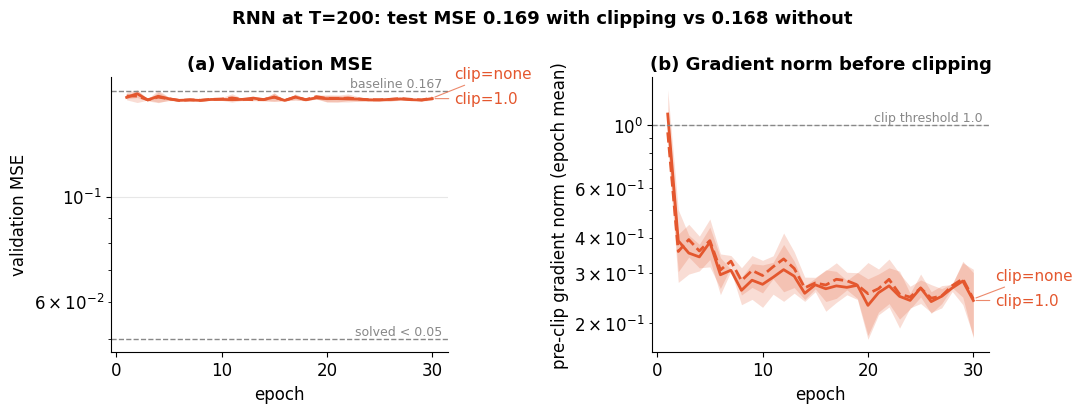

In [19]:
# P1.5c: the clip=1.0 arm is the P1.4 RNN T=200 run; only the no-clip arm is trained here.
CLIP = {
    "clip=1.0": ADD[("RNN", 200)],
    "clip=none": [
        run_cached("P1.5c-clip", "RNN", s, 200, f"h={H},clip=none", lambda s=s: run_add("RNN", s, 200, clip=None))
        for s in SEEDS
    ],
}
cm_mse = {lab: [o["row"]["test_mse"] for o in runs] for lab, runs in CLIP.items()}
display(
    pd.DataFrame(
        [
            (
                lab,
                mean_std(v),
                f"{sum(m < 0.05 for m in v)}/{len(v)}",
                f"{max(max(o['history']['grad_norm']) for o in CLIP[lab]):.1f}",
            )
            for lab, v in cm_mse.items()
        ],
        columns=["RNN, T=200", "test MSE (mean ± std)", "solved", "max pre-clip grad norm"],
    )
)

# P1-F7: (a) validation MSE, (b) gradient norm before clipping.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
ep = np.arange(1, EPOCHS + 1)
for lab, ls in (("clip=1.0", "-"), ("clip=none", "--")):
    band(ax1, ep, [o["history"]["val_loss"] for o in CLIP[lab]], lab, COLORS["RNN"], ls)
    band(ax2, ep, [o["history"]["grad_norm"] for o in CLIP[lab]], lab, COLORS["RNN"], ls)
ref_line(ax1, 0.167, "baseline 0.167")
ref_line(ax1, 0.05, "solved < 0.05")
ref_line(ax2, 1.0, "clip threshold 1.0")
for ax in (ax1, ax2):
    ax.set_yscale("log")
    ax.set_xlabel("epoch")
    end_labels(ax, log=True, gap=0.09)
ax1.set_ylabel("validation MSE")
ax1.set_title("(a) Validation MSE")
ax2.set_ylabel("pre-clip gradient norm (epoch mean)")
ax2.set_title("(b) Gradient norm before clipping")
m1, m0 = np.mean(cm_mse["clip=1.0"]), np.mean(cm_mse["clip=none"])
fig.suptitle(f"RNN at T=200: test MSE {m1:.3f} with clipping vs {m0:.3f} without", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "p1_fig07_ablation_clip")
plt.show()

### (d) Analysis
All numbers come from the Colab T4 run (h = 128, seeds 7, 21 and 42, mean ± sample std).

1. Memory, from the gradient plot (P1-F5). The loss is taken at the last step, so the gradient travels from t = 100 back to t = 1. Before training, less than 1e-19 of it reaches t = 1 in all three models. After training, the gradient at t = 1 divided by the gradient at t = 100 is 2.3e-19 for the RNN, 2.3e-05 for the LSTM and 0.58 for the GRU. So only the GRU sends a usable error signal back to the first marker. The RNN sends almost nothing, and the LSTM about 1e-5 of what the last step gets. These curves were computed with our P1.2 cells and the trained library weights, because cuDNN does not expose per-step hidden-state gradients.
2. Failure as T grows (P1-T2, P1-T3, P1-F4). The RNN never does better than predicting a constant. Its test MSE is 0.173, 0.170, 0.169 and 0.154 for T = 50, 100, 200 and 400, and it solves 0 of 3 runs at every length. The LSTM solves T = 50 (3/3, MSE 0.0072), only 1 of 3 runs at T = 100 (MSE 0.089 ± 0.077), and none at T = 200 or 400 within 30 epochs. The GRU solves T = 50, 100 and 200 for all three seeds (MSE 0.0013, 0.0013 and 0.0006) and 2 of 3 runs at T = 400 (MSE 0.028 ± 0.046; the failed seed ends at 0.082). This is the same order as in P1-F5. The clipping ablation (P1-F7) makes no difference for the RNN: test MSE is 0.1685 with clipping at 1.0 and 0.1683 without, and no run is solved in either arm. The largest epoch-mean gradient norm before clipping is 1.3 with clipping and 1.0 without, so the clip rarely does anything. The RNN fails because almost no gradient reaches the early marker (P1-F5), and clipping only limits large gradients.
3. Accuracy, parameters and time (P1-T1, P1-F6). On HAR the GRU (0.9115 ± 0.0061, 54,150 parameters, 0.30 s/epoch) and the LSTM (0.9108 ± 0.0133, 71,942 parameters, 0.39 s/epoch) are within one standard deviation of each other. Both are about 10 points above the RNN (0.8057 ± 0.0317, 18,566 parameters, 0.30 s/epoch). The GRU gets the same accuracy as the LSTM with 25% fewer parameters and a shorter epoch. In the hidden-size sweep (P1-F6a) accuracy drops slowly as h gets smaller: 0.9115, 0.9083, 0.8966 and 0.8792 for the GRU at h = 128, 64, 32 and 16, and 0.9108, 0.8984, 0.8689 and 0.8588 for the LSTM. For any parameter count the GRU curve is above the LSTM curve (P1-F6b).
4. Choice for a battery-powered wearable (P1-T1, P1-F6, P1-T3). I would use the GRU with h = 64. It has 14,790 parameters, which is 3.7 times fewer than the h = 128 GRU and 4.9 times fewer than the h = 128 LSTM, and its accuracy of 0.9083 is only 0.3 points below the best model. The GRU is also the only cell that kept long-range memory on the adding problem (P1-T3, P1-F5). The RNN is the smallest model, but it is 10 points less accurate on HAR, which rules it out. One limitation: s/epoch measures training time on a GPU, not energy on the device. The battery argument therefore rests on the parameter count, since memory use and multiply-adds per step grow with it.